# Advanced NLP Lab: Sentiment Analysis on Customer Feedback


---


By : Rajdeep Ghosh, Research Scholar, CSE-IITKGP

Reach out at [Linkedin](https://www.linkedin.com/in/ghoshrajdeep2000/) / Email: ghoshrajdeep2000@gmail.com



## 1. Why this problem matters

Customer feedback — product reviews, support tickets, app-store comments, survey free-text, social mentions — is the single largest source of *unstructured* text most organisations own. It arrives continuously, in volumes no team can read manually, and it directly encodes what customers want, what is broken, and who is about to churn.

**Sentiment analysis** is the task of automatically assigning an affective label (typically `negative` / `neutral` / `positive`) to a piece of text. It is the entry point to a broader family of *opinion mining* tasks:

| Task | Question it answers | Example output |
|---|---|---|
| Document sentiment | How does this customer feel overall? | `negative (0.94)` |
| Aspect-based sentiment (ABSA) | What *specifically* did they like or dislike? | `food: positive`, `service: negative` |
| Emotion detection | *Which* negative emotion? | `anger` vs `sadness` |
| Intent / topic routing | Who should handle this? | `billing`, `delivery` |

A production feedback system needs all four. This lab builds all four.

## 2. What you will build

We follow the standard modelling progression used in industry, measuring at every step so that each added layer of complexity has to *earn its place*:

```
Raw reviews
   │
   ├─▶ [A] TF-IDF + Linear model          ← classical baseline, seconds to train
   ├─▶ [B] Frozen transformer embeddings  ← no fine-tuning, one linear layer
   ├─▶ [C] Fine-tuned RoBERTa             ← full supervised fine-tuning
   │
   └─▶ Beyond a single label:
         • Emotion classification
         • Aspect-Based Sentiment Analysis (ABSA)
         • Zero-shot topic routing
         • Explainability (LIME)
         • Error analysis & calibration
         • Packaging an inference service
```

## 3. Learning outcomes

By the end of this lab you will be able to:

1. Build and evaluate a **strong classical baseline** and explain exactly where bag-of-words representations break down.
2. Distinguish **frozen embeddings + classifier head** from **full fine-tuning**, and quantify the accuracy/cost trade-off.
3. Fine-tune a transformer encoder with the Hugging Face `Trainer`, using **class weighting** and **macro-F1** to handle imbalance correctly.
4. Extract **aspect-level** sentiment so that a single "negative" label becomes an actionable engineering ticket.
5. **Explain** individual predictions and run a structured **error analysis** (negation, contrast, sarcasm, calibration).
6. Package the result as a **feedback triage service**.




---
# Part 0 — Environment Setup

`Runtime` → `Change runtime type` → **Hardware accelerator: T4 GPU** → `Save`.

Everything in this notebook *runs* on CPU, but Part 4 (fine-tuning) takes ~5 minutes on a T4 versus ~1 hour on CPU. The notebook detects the hardware and shrinks the training set automatically if no GPU is present, so it will still complete either way.

In [ ]:
# because we install BEFORE importing any of these libraries.
%pip install -q -U "transformers>=4.44" "datasets>=2.19" "accelerate>=0.31" "sentence-transformers>=3.0" sentencepiece protobuf lime scikit-learn pandas matplotlib

print("Install step finished.")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
Install step finished.


In [ ]:
# ---------------------------------------------------------------------
# Imports and global configuration
# ---------------------------------------------------------------------
import os, re, json, time, random, warnings, textwrap
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 160)

SEED = 42

def set_seed(seed=SEED):
    '''Seed every RNG we touch so the lab is reproducible across reruns.'''
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

# Detect hardware. `DEVICE` is used by PyTorch; `PIPE_DEVICE` is the integer that
# Hugging Face `pipeline(...)` expects (0 = first GPU, -1 = CPU).
HAS_GPU     = torch.cuda.is_available()
DEVICE      = torch.device("cuda" if HAS_GPU else "cpu")
PIPE_DEVICE = 0 if HAS_GPU else -1

print(f"torch     : {torch.__version__}")
print(f"GPU       : {torch.cuda.get_device_name(0) if HAS_GPU else 'NOT AVAILABLE (running in reduced mode)'}")
print(f"device    : {DEVICE}")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


torch     : 2.11.0+cu130
GPU       : Tesla T4
device    : cuda


In [ ]:
# ---------------------------------------------------------------------
# Lab configuration. Change these to trade runtime against accuracy.
# FAST_MODE shrinks every expensive step; it turns on automatically without a GPU.
# ---------------------------------------------------------------------
FAST_MODE = not HAS_GPU

CFG = {
    # --- data ---
    "train_n":     4000 if FAST_MODE else 16000,   # labelled examples used for training
    "val_n":       1000 if FAST_MODE else  2000,   # used for early model selection
    "test_n":      1500 if FAST_MODE else  4000,   # held out until the very end
    # --- fine-tuning ---
    "model_name":  "distilroberta-base" if FAST_MODE else "roberta-base",
    "max_len":     128 if FAST_MODE else 192,      # tokens; reviews longer than this are truncated
    "epochs":      1 if FAST_MODE else 2,
    "batch_size":  16 if FAST_MODE else 32,
    "lr":          2e-5,                            # standard LR for encoder fine-tuning
    "weight_decay": 0.01,
    "warmup_ratio": 0.06,
}

for k, v in CFG.items():
    print(f"{k:>14} : {v}")
print(f"\n{'FAST_MODE' if FAST_MODE else 'FULL MODE'} enabled.")

       train_n : 16000
         val_n : 2000
        test_n : 4000
    model_name : roberta-base
       max_len : 192
        epochs : 2
    batch_size : 32
            lr : 2e-05
  weight_decay : 0.01
  warmup_ratio : 0.06

FULL MODE enabled.


---
# Part 1 — The Dataset

## 1.1 Choosing a corpus

We use the **Yelp Review Full** dataset (Zhang, Zhao & LeCun, 2015) — ~700k real customer reviews of businesses (restaurants, salons, garages, hotels), each with the **star rating the customer actually gave**.

It is a good teaching corpus for four reasons:

1. **It is genuinely real.** Typos, slang, ALL CAPS, sarcasm, run-on sentences, mixed opinions in one review — none of it is cleaned up.
2. **Labels are user-provided, not annotator-provided.** The star rating *is* the customer's own verdict. That removes annotator subjectivity but introduces a different problem we will discuss below.
3. **Reviews are long and multi-topic** ("food was great, service was a disaster"). That is exactly what makes aspect-based sentiment necessary in Part 6.
4. **It is a canonical benchmark**, so your numbers are comparable with published results.

The loader below tries several sources in order and falls back to an Amazon app-review CSV hosted on GitHub if the Hugging Face Hub is unreachable. Everything downstream reads the labels dynamically, so the notebook completes either way.

In [ ]:

from datasets import load_dataset

# Each entry: (loader callable, human-readable name).
# The loaders are tried in order, and execution stops after the first successful load.
def _load_yelp(dataset_id):
    # Load the Yelp dataset's training split from Hugging Face.
    ds = load_dataset(dataset_id, split="train")

    # Convert the dataset to a DataFrame.
    # Yelp labels are 0-4, so add 1 to represent the original 1-5 star ratings.
    df = pd.DataFrame({
        "text": ds["text"],
        "stars": np.array(ds["label"]) + 1
    })

    return df, "stars"



# Define the dataset sources in priority order.
# If one source fails, the next available source will be attempted.
SOURCES = [
    # Standard Hugging Face Yelp Review Full dataset.
    (lambda: _load_yelp("yelp_review_full"), "Yelp Review Full (Hugging Face)"),

    # Namespaced alternative for the same Yelp dataset.
    (lambda: _load_yelp("Yelp/yelp_review_full"), "Yelp Review Full (namespaced id)"),
]

# Initialize variables so we can detect if every source fails.
raw_df, LABEL_SOURCE, SOURCE_NAME = None, None, None

# Try each dataset source until one loads successfully.
for loader, name in SOURCES:
    try:
        # Record the start time so we can report how long loading took.
        t0 = time.time()

        # Run the current loader and store the resulting DataFrame and label type.
        raw_df, LABEL_SOURCE = loader()

        # Remember which source was successfully loaded.
        SOURCE_NAME = name

        # Report successful loading and the number of reviews retrieved.
        print(
            f"Loaded '{name}' -> "
            f"{len(raw_df):,} reviews in {time.time() - t0:.1f}s"
        )

        # Stop trying additional sources after the first successful load.
        break

    except Exception as e:
        # If the current source fails, report the error and continue to the next one.
        print(
            f"[skip] {name}: "
            f"{type(e).__name__}: {str(e)[:120]}"
        )

# Raise an error if none of the dataset sources could be loaded.
if raw_df is None:
    raise RuntimeError(
        "No dataset source reachable. "
        "Check the Colab network connection and rerun."
    )

# Remove rows where the review text is missing.
# reset_index() creates a clean sequential index after rows are removed.
raw_df = raw_df.dropna(subset=["text"]).reset_index(drop=True)


raw_df.head(3) # Display the first three reviews to verify that the dataset loaded correctly.



README.md:   0%|          | 0.00/6.72k [00:00<?, ?B/s]

[skip] Yelp Review Full (Hugging Face): HfUriError: Invalid HF URI 'hf://datasets/yelp_review_full@c1f9ee939b7d05667af864ee1cb066393154bf85/.huggingface.yaml'. Repository i


README.md:   0%|          | 0.00/6.72k [00:00<?, ?B/s]

yelp_review_full/train-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  299MB            

yelp_review_full/train-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

yelp_review_full/test-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B / 23.5MB            

yelp_review_full/test-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/650000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Loaded 'Yelp Review Full (namespaced id)' -> 650,000 reviews in 26.8s


,text,stars
0,dr. goldberg offers everything i look for in a general practitioner. he's nice and easy to talk to without being patronizing; he's always on time in seeing...,5
1,"Unfortunately, the frustration of being Dr. Goldberg's patient is a repeat of the experience I've had with so many other doctors in NYC -- good doctor, terr...",2
2,Been going to Dr. Goldberg for over 10 years. I think I was one of his 1st patients when he started at MHMG. He's been great over the years and is really al...,4


## 1.2 Turning ratings into sentiment labels

Star ratings are **ordinal**, sentiment labels are **categorical**. Collapsing 5 stars into 3 classes is a modelling decision, not a neutral preprocessing step, and it is worth being explicit about it:

| Stars | Label | Rationale |
|---|---|---|
| 1 – 2 | `negative` | Unambiguous dissatisfaction |
| 3 | `neutral` | Mixed or lukewarm; the hardest class by far |
| 4 – 5 | `positive` | Unambiguous satisfaction |

**Why 3-star = neutral is the interesting case.** A 3-star review is rarely emotionally neutral. It is usually *mixed*: "great food, terrible wait". Forcing it into a single label loses information — which is precisely the motivation for aspect-based sentiment analysis later.

> **Label noise warning.** Star ratings are a *proxy* for sentiment, not sentiment itself. Customers rate for reasons the text never mentions (a late delivery, a coupon that failed). Published human–star agreement on review corpora sits in the 80–90% range, so treat ~90% as a soft ceiling on accuracy, not a target to beat.

In [ ]:
# Map the raw rating/label column to a canonical `sentiment` string column.
# This keeps the downstream pipeline independent of the original dataset format.
def stars_to_sentiment(s):
    # Ratings of 1-2 stars are treated as negative sentiment.
    if s <= 2:
        return "negative"

    # A 3-star rating is treated as neutral sentiment.
    if s == 3:
        return "neutral"

    # Ratings of 4-5 stars are treated as positive sentiment.
    return "positive"


# Apply the appropriate label conversion based on the dataset source.
if LABEL_SOURCE == "stars":
    # Convert Yelp's 1-5 star ratings into three sentiment classes.
    raw_df["sentiment"] = raw_df["stars"].apply(stars_to_sentiment)
else:
    # Convert binary labels into the canonical negative/positive classes.
    # Binary labels use 0 = negative and 1 = positive.
    raw_df["sentiment"] = raw_df["binary"].map({
        0: "negative",
        1: "positive"
    })


# Define the canonical class ordering: negative -> neutral -> positive.
# Only include classes that are actually present in the loaded dataset.
LABELS = [
    c for c in ["negative", "neutral", "positive"]
    if c in set(raw_df["sentiment"])
]

# Create mappings between sentiment names and integer IDs.
# These mappings are useful for model training and evaluation.
LABEL2ID = {label: idx for idx, label in enumerate(LABELS)}
ID2LABEL = {idx: label for label, idx in LABEL2ID.items()}

# Store the total number of sentiment classes.
NUM_LABELS = len(LABELS)


# Display information about the dataset and its sentiment classes.
print("Source        :", SOURCE_NAME)
print("Classes       :", LABELS)

# Display the number of examples in each sentiment class.
print("\nClass counts:")
print(raw_df["sentiment"].value_counts()[LABELS])

# Display the proportion of examples belonging to each sentiment class.
# Rounding to three decimal places makes the output easier to read.
print("\nProportions:")
print(
    raw_df["sentiment"]
    .value_counts(normalize=True)[LABELS]
    .round(3)
)

Source        : Yelp Review Full (namespaced id)
Classes       : ['negative', 'neutral', 'positive']

Class counts:
sentiment
negative    260000
neutral     130000
positive    260000
Name: count, dtype: int64

Proportions:
sentiment
negative    0.4
neutral     0.2
positive    0.4
Name: proportion, dtype: float64


## 1.3 Exploratory data analysis

Never train before looking. Three things drive almost every downstream decision:

1. **Class balance** → determines the metric (`macro-F1`, not accuracy) and whether we need class weights.
2. **Length distribution** → determines `max_len` for tokenisation, i.e. how much text we silently throw away.
3. **Class-distinctive vocabulary** → a sanity check that the signal is where you think it is.

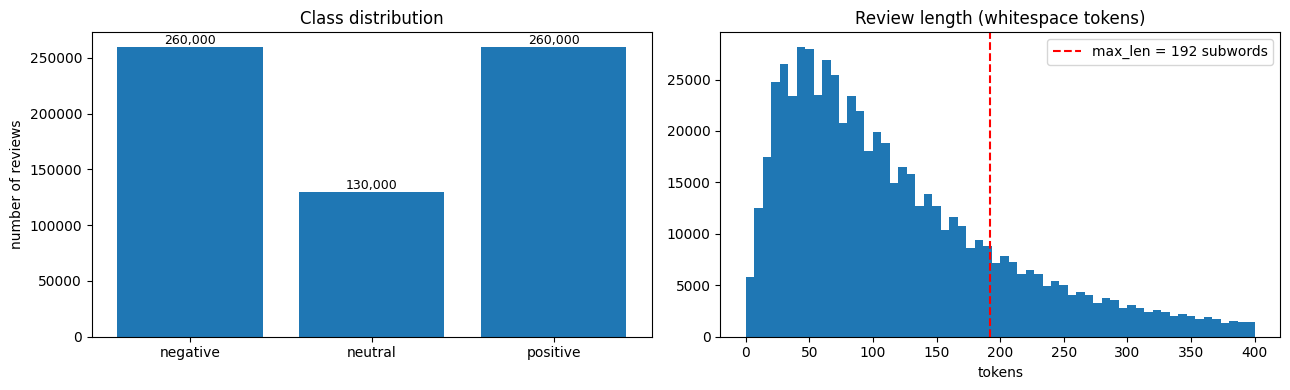

count    650000.0
mean        134.1
std         121.4
min           1.0
50%          99.0
75%         175.0
90%         282.0
95%         370.0
99%         601.0
max        1052.0
Name: text, dtype: float64

Reviews longer than 192 words: 21.5%  <- these get truncated during fine-tuning


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# --- (a) class balance ---
counts = raw_df["sentiment"].value_counts()[LABELS]
axes[0].bar(counts.index, counts.values)
axes[0].set_title("Class distribution")
axes[0].set_ylabel("number of reviews")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)

# --- (b) review length in whitespace tokens (a cheap proxy for subword count) ---
lengths = raw_df["text"].str.split().str.len()
axes[1].hist(lengths, bins=60, range=(0, 400))
axes[1].axvline(CFG["max_len"], linestyle="--", color="red",
                label=f"max_len = {CFG['max_len']} subwords")
axes[1].set_title("Review length (whitespace tokens)")
axes[1].set_xlabel("tokens"); axes[1].legend()

plt.tight_layout(); plt.show()

print(lengths.describe(percentiles=[.5, .75, .9, .95, .99]).round(1))
print(f"\nReviews longer than {CFG['max_len']} words: "
      f"{(lengths > CFG['max_len']).mean():.1%}  <- these get truncated during fine-tuning")

**Reading the length plot.** Subword tokenisation produces roughly 1.3× the number of whitespace tokens, so the red line is optimistic. Truncation is not free: sentiment is often concentrated in the *final* sentence of a review ("...but overall I won't be back"). Truncating from the right removes exactly that. Two standard remedies:

- **Head+tail truncation** — keep the first *k* and last *m* tokens (Sun et al., *How to Fine-Tune BERT for Text Classification?*, 2019).
- **Long-context encoders** — Longformer, BigBird, or a modern long-context model.

We accept plain right-truncation here for speed, and revisit its cost in the error analysis.

In [ ]:
# To identify and inspect the vocabulary that is statistically most distinctive for each sentiment class, rather than simply looking at the most frequent words.
# ---------------------------------------------------------------------
# Identify class-distinctive vocabulary using the log-count ratio.
#
# score(w, c) = log(P(w | c) / P(w | not c))
#
# A positive score means a word/ngram is more strongly associated with
# class `c` than with the other classes. Add-1 smoothing prevents zero
# counts from producing undefined ratios.
# ---------------------------------------------------------------------

from sklearn.feature_extraction.text import CountVectorizer

# Use at most 20,000 reviews for EDA to keep the vocabulary analysis efficient.
# A fixed random seed ensures the same sample is selected across runs.
eda_sample = raw_df.sample(
    min(20000, len(raw_df)),
    random_state=SEED
)

# Build a bag-of-words representation using unigrams and bigrams.
# - min_df=15 removes very rare terms.
# - max_features=30000 limits the vocabulary size.
# - stop_words="english" removes common English stopwords.
cv = CountVectorizer(
    min_df=15,
    max_features=30000,
    stop_words="english",
    ngram_range=(1, 2)
)

# Fit the vectorizer on the EDA sample and transform the reviews into
# a sparse document-term count matrix.
X_eda = cv.fit_transform(eda_sample["text"])

# Store the vocabulary as a NumPy array so it can be indexed efficiently.
vocab = np.array(cv.get_feature_names_out())


# Calculate the most distinctive words/ngrams for each sentiment class.
for label in LABELS:
    # Create a boolean mask selecting reviews belonging to the current class.
    mask = (eda_sample["sentiment"] == label).values

    # Count occurrences of every vocabulary item within the current class.
    # Add 1 to every count for add-one (Laplace) smoothing.
    in_cls = np.asarray(
        X_eda[mask].sum(axis=0)
    ).ravel() + 1

    # Count occurrences of every vocabulary item outside the current class.
    # Add 1 here as well so both probability estimates are non-zero.
    out_cls = np.asarray(
        X_eda[~mask].sum(axis=0)
    ).ravel() + 1

    # Convert the smoothed counts into class-conditional probabilities
    # and compute the log-count ratio for every vocabulary item.
    ratio = np.log(
        (in_cls / in_cls.sum()) /
        (out_cls / out_cls.sum())
    )

    # Select the 12 vocabulary items with the largest log-count ratios.
    # Larger values indicate stronger association with the current class.
    top = vocab[np.argsort(-ratio)[:12]]

    # Print the class name followed by its most distinctive terms.
    print(f"{label:>9} | " + ", ".join(top))


 negative | worst experience, zero stars, horrible customer, poisoning, food poisoning, negative stars, big mistake, awful service, terrible customer, took car, awful experience, bait switch
  neutral | decent place, hipsters, food bit, salad pretty, mixed feelings, wow factor, pretty expensive, souffle, bit overpriced, nwould come, moderately priced, ok like
 positive | hands best, nwe definitely, wonderfully, place amazing, dark chocolate, feel right, love love, staff amazing, gem, great work, glad did, hidden gem


In [ ]:
# Read a few real examples end to end --
for label in LABELS:
    ex = raw_df[raw_df["sentiment"] == label].sample(1, random_state=SEED).iloc[0]
    print("=" * 100)
    print(f"[{label.upper()}]")
    print(textwrap.fill(ex["text"][:700], 100))
print("=" * 100)

[NEGATIVE]
Awful service, awful food.\n\nWas here several weeks ago as part of a large group; I arrived partway
through the meal and did not order anything, so can't speak for the food on that occasion (though it
looked good), but the service was excellent. We had a male waiter who handled our giant group with
ease and was very pleasant.\n\nThis time, we had a girl serving us. I did not catch her name, but
she was short, kinda squat and had darker hair. She seemed to have a bit of an attitude, and was
nowhere to be found when we needed refills, dressing, or the check. Another server also delivered
all our beer from the bar, so she must have really been pulling a vanishing act.\n\nAs for the
food... We
[NEUTRAL]
If you go in for theme restaurants,this one is tops. A neat place to take people--if you can,ask to
sit inside one of the boats!  Kids love this place.But be forewarned-if you are having a nice lunch
or dinner in one of the 'boats',you may get some uninvited company in the form 


Print **five** reviews from the hardest class and read them carefully. Answer in a comment:

- How many are *genuinely* lukewarm, versus *mixed* (positive about one aspect, negative about another)?
- What would a single-label classifier have to learn to get these right?



In [ ]:
hard = "neutral" if "neutral" in LABELS else "negative"
for _, r in raw_df[raw_df.sentiment == hard].sample(5, random_state=1).iterrows():
    print(textwrap.fill(r.text[:500], 100), "\n" + "-"*100)

We went after 9pm, they have a special menu.  You need to ask for it.  We ordered 9 dishes, these
are the ones that suck out in my mind:\n\n1.  Peking Spare Ribs - Flavorful, crispy, and just so
good.\n2.  Rice soup with shredded pork and preserved egg - not enough flavor.\n3.  Fried Flounder -
Crispy, fresh, and the sauce on the side was with a hint of spicy\n4.  Sliced fish with greens -
fish was fresh and soft, needed a little more flavor\n5.  Beef stew hot pot - the beef was tender,
radish w 
----------------------------------------------------------------------------------------------------
Oh the things I have seen here. A lovely combination of disgusting and endless comic relief. If you
go in only with the expectation of seeing a sh*t show, you will not be disappointed.\n\nThe locals
know this as a tourist spot, but will come on occasion (likely to prey on young, drunk
Americans).\n\nTo re-iterate a commonly used word in other reviews: sloppy. 
----------------------------------

Typically 3–4 of 5 are mixed, not lukewarm. A single-label model has to learn an implicit aggregation rule over aspects — which is not stated anywhere in the training signal and differs customer to customer. This is the fundamental ceiling on document-level sentiment, and the motivation for ABSA in Part 6.

## 1.4 Train / validation / test split

Three splits, three distinct jobs:

- **train** — fit parameters.
- **validation** — choose hyperparameters, epochs, thresholds. Touched many times.
- **test** — touched **once**, at the very end. Every time you look at test and change something, it silently becomes a validation set and your reported number becomes optimistic.

We **stratify** by class so the proportions are identical in all three splits, and subsample to keep the lab inside its time budget.

In [ ]:
from sklearn.model_selection import train_test_split

# 1) Draw a working pool, 2) deduplicate, 3) split. Order matters: deduplicating AFTER
#    splitting would leave near-identical reviews on both sides of the boundary, which
#    inflates test scores (a classic and easy-to-miss leakage bug in scraped corpora).
total_n = CFG["train_n"] + CFG["val_n"] + CFG["test_n"]
pool = raw_df.sample(min(total_n * 3, len(raw_df)), random_state=SEED)

norm = pool["text"].str.lower().str.replace(r"\W+", " ", regex=True).str.strip()
pool = pool[~norm.duplicated()].reset_index(drop=True)
print(f"Pool after dedup: {len(pool):,} reviews")

# Clamp the requested sizes to what is actually available.
avail   = len(pool)
n_test  = min(CFG["test_n"],  int(avail * 0.25))
n_val   = min(CFG["val_n"],   int(avail * 0.12))
n_train = min(CFG["train_n"], avail - n_test - n_val)

train_df, rest = train_test_split(pool, train_size=n_train,
                                  stratify=pool["sentiment"], random_state=SEED)
val_df, test_df = train_test_split(rest, train_size=n_val,
                                   stratify=rest["sentiment"], random_state=SEED)
if len(test_df) > n_test:
    test_df = test_df.sample(n_test, random_state=SEED)

train_df, val_df, test_df = (d.reset_index(drop=True) for d in (train_df, val_df, test_df))

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    dist = d["sentiment"].value_counts(normalize=True)[LABELS].round(3).to_dict()
    print(f"{name:>5}: {len(d):>6,} rows   {dist}")

# Integer label column used by every model from here on.
for d in (train_df, val_df, test_df):
    d["y"] = d["sentiment"].map(LABEL2ID)

Pool after dedup: 65,989 reviews
train: 16,000 rows   {'negative': 0.4, 'neutral': 0.201, 'positive': 0.398}
  val:  2,000 rows   {'negative': 0.4, 'neutral': 0.202, 'positive': 0.398}
 test:  4,000 rows   {'negative': 0.389, 'neutral': 0.214, 'positive': 0.397}


## 1.5 The evaluation protocol

Fix the metric **before** modelling, otherwise you will unconsciously pick the metric that flatters your model.

- **Accuracy** is misleading under imbalance: predicting the majority class alone already scores well.
- **Macro-F1** averages F1 over classes *without* weighting by class size, so the rare, hard class counts as much as the easy majority. **This is our headline metric.**
- **Per-class precision/recall** is what you actually take to a product owner: "we catch 78% of angry customers, and 1 in 5 of our alerts is a false alarm."

In [ ]:
# Import evaluation metrics and utilities from scikit-learn.
from sklearn.metrics import (
    accuracy_score,          # Overall percentage of correct predictions.
    f1_score,                # F1 score, combining precision and recall.
    classification_report,  # Detailed precision, recall, and F1 per class.
    confusion_matrix,        # Computes the confusion matrix.
    ConfusionMatrixDisplay   # Convenient visualisation of the confusion matrix.
)

# Store evaluation results for every model.
# Each entry will contain the model's accuracy and macro-F1 score.
RESULTS = {}   # model_name -> {"accuracy": ..., "macro_f1": ...}


def evaluate(y_true, y_pred, name, show_report=True, show_cm=True):
    """
    Evaluate a model's predictions and optionally display detailed results.

    Parameters:
        y_true: Actual labels from the test set.
        y_pred: Labels predicted by the model.
        name: Name used to identify the model in RESULTS and printed output.
        show_report: Whether to print the classification report.
        show_cm: Whether to display the confusion matrix.

    Returns:
        Tuple containing (accuracy, macro_f1).
    """

    # Calculate overall accuracy:
    # number of correct predictions / total number of predictions.
    acc = accuracy_score(y_true, y_pred)

    # Calculate macro-F1 by computing F1 separately for each class
    # and then taking their unweighted average.
    # This gives every class equal importance, regardless of class size.
    f1 = f1_score(y_true, y_pred, average="macro")

    # Save the evaluation results so models can be compared later.
    RESULTS[name] = {
        "accuracy": acc,
        "macro_f1": f1
    }

    # Print the model name and its main evaluation metrics.
    print(f"=== {name} ===")
    print(f"accuracy : {acc:.4f}")
    print(f"macro-F1 : {f1:.4f}\n")

    # Optionally display precision, recall, and F1 score for each class.
    if show_report:
        print(
            classification_report(
                y_true,
                y_pred,
                target_names=LABELS,
                digits=3
            )
        )

    # Optionally create and display a row-normalised confusion matrix.
    if show_cm:
        # Normalize each row so that values represent the proportion
        # of examples from each true class assigned to each predicted class.
        # Therefore, the diagonal values correspond to recall per class.
        cm = confusion_matrix(
            y_true,
            y_pred,
            normalize="true"
        )

        # Create a figure and axis for the confusion matrix.
        fig, ax = plt.subplots(figsize=(4.6, 4.2))

        # Plot the normalized confusion matrix with sentiment labels.
        ConfusionMatrixDisplay(
            cm,
            display_labels=LABELS
        ).plot(
            ax=ax,
            colorbar=False,
            values_format=".2f",
            cmap="Blues"
        )

        # Add a title explaining how the matrix is normalized.
        ax.set_title(
            f"{name}\n"
            "(row-normalised = recall per class)"
        )

        # Adjust spacing so labels and the title fit neatly.
        plt.tight_layout()

        # Display the confusion matrix.
        plt.show()

    # Return the two main metrics for possible later use.
    return acc, f1



In [ ]:

# ---------------------------------------------------------------------
# Majority-class baseline
# ---------------------------------------------------------------------
# Establish a simple reference point before evaluating real models.
# The baseline always predicts whichever class occurs most frequently
# in the training set.
#
# Any useful trained model should ideally outperform this baseline.
# ---------------------------------------------------------------------

# Find the most common encoded label in the training data.
majority = train_df["y"].value_counts().idxmax()

# Predict the majority class for every example in the test set.
# np.full() creates an array with the same prediction repeated
# for every test example.
majority_predictions = np.full(
    len(test_df),
    majority
)

# Evaluate the trivial majority-class classifier.
# The confusion matrix is disabled because this baseline is only being
# used as a simple reference point.
evaluate(
    test_df["y"],
    majority_predictions,
    "Majority-class baseline",
    show_cm=False
)

=== Majority-class baseline ===
accuracy : 0.3892
macro-F1 : 0.1868

              precision    recall  f1-score   support

    negative      0.389     1.000     0.560      1557
     neutral      0.000     0.000     0.000       855
    positive      0.000     0.000     0.000      1588

    accuracy                          0.389      4000
   macro avg      0.130     0.333     0.187      4000
weighted avg      0.152     0.389     0.218      4000



(0.38925, 0.18679143422710096)

---
# Part 2 — Baseline A: TF-IDF + Linear Classifier

Always build the boring baseline first. It takes two minutes, it is interpretable, it trains on a laptop, and it tells you whether the expensive model is worth its cost.

**TF-IDF** represents a document as a sparse vector over the vocabulary:

$$\text{tfidf}(t, d) = \underbrace{\big(1 + \log \text{tf}(t,d)\big)}_{\text{how often } t \text{ occurs in } d} \times \underbrace{\log \frac{N}{\text{df}(t)}}_{\text{how rare } t \text{ is overall}}$$

Two design choices that matter for sentiment specifically:

- **Word bigrams** (`ngram_range=(1,2)`) — the only way this representation can see `not good` as distinct from `good`.
- **Do not remove negation stopwords.** A default English stoplist deletes `not`, `no`, `never`, `nor`, which silently *inverts* the polarity of the text. We keep stopwords entirely and let the linear model down-weight them.

Trained in 20.8s on 16,000 reviews
Vocabulary size: 53,166 features
=== A. TF-IDF + LogisticRegression ===
accuracy : 0.7545
macro-F1 : 0.7125

              precision    recall  f1-score   support

    negative      0.816     0.818     0.817      1557
     neutral      0.507     0.476     0.491       855
    positive      0.817     0.843     0.830      1588

    accuracy                          0.754      4000
   macro avg      0.713     0.712     0.713      4000
weighted avg      0.750     0.754     0.752      4000



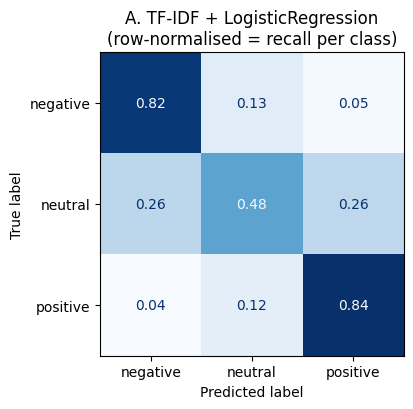

(0.7545, 0.7125235037545558)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline

# NOTE: no stop_words argument -> negation words survive. sublinear_tf applies the
# 1 + log(tf) damping above, which works better than raw counts on long reviews.
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=6,             # ignore terms in <3 documents (mostly typos)
    max_df=0.85,           # ignore terms in >90% of documents (uninformative)
    sublinear_tf=True,
    strip_accents="unicode",
)

# class_weight="balanced" reweights the loss by inverse class frequency, so the
# minority class is not simply ignored. This is the cheapest imbalance fix available.
baseline = make_pipeline(
    tfidf,
    LogisticRegression(max_iter=2000, C=4.0, class_weight="balanced", n_jobs=-1),
)

t0 = time.time()
baseline.fit(train_df["text"], train_df["y"])
print(f"Trained in {time.time()-t0:.1f}s on {len(train_df):,} reviews")
print(f"Vocabulary size: {len(baseline.named_steps['tfidfvectorizer'].vocabulary_):,} features")

pred_tfidf = baseline.predict(test_df["text"])
evaluate(test_df["y"], pred_tfidf, "A. TF-IDF + LogisticRegression")

## 2.1 Reading the model's mind

A linear model over TF-IDF features is fully interpretable: each coefficient is the (log-odds) contribution of one n-gram to one class. Inspect them — this is your fastest route to spotting leakage or a corrupted label mapping.

In [ ]:
# ---------------------------------------------------------------------
# Inspect the most influential TF-IDF features learned by the linear
# logistic-regression model.
#
# Each coefficient indicates how strongly an n-gram contributes toward
# a particular class. Inspecting these features helps us understand
# what the model has learned and can reveal:
#   - sensible sentiment words,
#   - unexpected features,
#   - label-mapping mistakes,
#   - possible data leakage.
# ---------------------------------------------------------------------

# Extract the fitted TF-IDF vectorizer from the trained pipeline.
# This converts the model's feature indices back into readable words
# and n-grams.
vec = baseline.named_steps["tfidfvectorizer"]

# Extract the fitted logistic-regression classifier from the pipeline.
clf = baseline.named_steps["logisticregression"]

# Get the complete vocabulary learned by the TF-IDF vectorizer.
# The order of these features matches the columns of clf.coef_.
feat = np.array(vec.get_feature_names_out())


# Inspect the most strongly associated features for each sentiment class.
for i, label in enumerate(LABELS):

    # For multiclass logistic regression, sklearn stores one coefficient
    # vector per class, so we can directly use clf.coef_[i].
    #
    # For binary classification, sklearn stores only ONE coefficient row.
    # That row represents the positive class. Therefore:
    #   - positive-class coefficients are used as-is,
    #   - negative-class coefficients are obtained by reversing the sign.
    #
    # This makes the coefficient interpretation consistent for every class.
    if clf.coef_.shape[0] > 1:
        coefs = clf.coef_[i]
    else:
        coefs = clf.coef_[0] * (1 if i == 1 else -1)

    # Sort features from the largest positive coefficient to the smallest.
    # The largest coefficients are the n-grams most strongly associated
    # with the current class.
    top = feat[np.argsort(-coefs)[:15]]

    # Print the 15 most influential features for the current class.
    print(f"{label:>9} | " + ", ".join(top))

 negative | not, horrible, worst, will not, rude, no, money, terrible, mediocre, never, overpriced, two stars, awful, not good, the worst
  neutral | but, ok, average, three stars, good, decent, however, pretty, was good, though, stars, not bad, pretty good, sometimes, okay
 positive | great, delicious, amazing, awesome, excellent, love, perfect, best, fantastic, wonderful, definitely, always, will definitely, yummy, recommend


## 2.2 Where bag-of-words breaks

TF-IDF has no notion of word order beyond the n-grams you explicitly gave it, and no notion of meaning at all. Four failure families dominate:

| Failure | Example | Why TF-IDF fails |
|---|---|---|
| Long-range negation | "I *cannot* say I *enjoyed* a single thing" | `enjoyed` is a strong positive unigram; `cannot` is 5 tokens away |
| Contrast | "The food was excellent, **but** the service ruined it" | Both polarities present; no way to know which one dominates |
| Comparison | "Better than the place next door, which is not saying much" | Requires pragmatic inference |
| Unseen vocabulary | "totally mid" | Not in the training vocabulary → contributes nothing |

Let's confirm this empirically rather than take it on faith.

In [ ]:
# Hand-written probes. Each pair differs by a single operator (negation / contrast)
# that flips or dominates the intended polarity.
PROBES = [
    ("The food was great.",                                          "positive"),
    ("The food was not great.",                                      "negative"),
    ("I would not say the food was bad.",                            "positive"),
    ("Great food, but the service completely ruined the evening.",   "negative"),
    ("Terrible parking, but honestly the meal was outstanding.",     "positive"),
    ("Well, that was exactly the experience I was hoping for. Not.", "negative"),
]

probe_texts  = [p[0] for p in PROBES]
probe_gold   = [p[1] for p in PROBES]
probe_pred   = [ID2LABEL[i] for i in baseline.predict(probe_texts)]
probe_proba  = baseline.predict_proba(probe_texts).max(axis=1)

probe_df = pd.DataFrame({"text": probe_texts, "expected": probe_gold,
                         "tfidf_pred": probe_pred, "confidence": probe_proba.round(2)})
probe_df["correct"] = probe_df.expected == probe_df.tfidf_pred
display(probe_df)
print(f"Probe accuracy: {probe_df.correct.mean():.0%}")

,text,expected,tfidf_pred,confidence,correct
0,The food was great.,positive,positive,0.95,True
1,The food was not great.,negative,negative,0.77,True
2,I would not say the food was bad.,positive,negative,0.95,False
3,"Great food, but the service completely ruined the evening.",negative,negative,0.51,True
4,"Terrible parking, but honestly the meal was outstanding.",positive,negative,0.70,False
5,"Well, that was exactly the experience I was hoping for. Not.",negative,negative,0.84,True


Probe accuracy: 67%


---
# Part 3 — Baseline B: Frozen Transformer Embeddings  

Between "TF-IDF" and "fine-tune the whole network" sits a much-underused middle option:

> Run a pretrained sentence encoder **once** over your corpus, cache the vectors, and train a
> cheap classifier on top. The transformer's weights are never updated.

Why it is worth knowing:

- **Cost.** One forward pass per document, no backward pass, no optimiser state. You can embed a million reviews on one GPU and then re-train the classifier head in seconds.
- **Reusability.** The same cached vectors serve classification, clustering, semantic search and near-duplicate detection.
- **Data efficiency.** With only a few hundred labels, fine-tuning overfits badly; a logistic regression on frozen embeddings often wins.

We use `all-MiniLM-L6-v2` — a 6-layer, 384-dimensional sentence-transformer trained with a contrastive objective on 1B+ sentence pairs. It is small (~80 MB) and fast, which is the point.

**Important caveat:** sentence-transformers are trained for *semantic similarity*, not sentiment. Two reviews with opposite polarity about the same dish are semantically close. That mismatch is exactly what we are about to measure.

In [ ]:
# Import the SentenceTransformer class for generating dense semantic embeddings.
from sentence_transformers import SentenceTransformer

# Specify the pretrained MiniLM sentence-embedding model.
# This model converts each review into a fixed-length numerical vector
# that captures semantic information about the text.
EMB_MODEL = "sentence-transformers/all-MiniLM-L6-v2"

# Load the pretrained encoder on the selected device (CPU or GPU).
encoder = SentenceTransformer(
    EMB_MODEL,
    device=str(DEVICE)
)

# Sentence embeddings are more computationally expensive than TF-IDF.
# In FAST_MODE, use fewer training examples to reduce runtime.
# Otherwise, use up to 12,000 training reviews.
emb_train = train_df.sample(
    min(
        len(train_df),
        4000 if FAST_MODE else 12000
    ),
    random_state=SEED
)

# Record the start time so we can measure the embedding generation time.
t0 = time.time()

# Convert the sampled training reviews into dense semantic vectors.
# - batch_size=128 processes 128 reviews at a time.
# - show_progress_bar=True displays encoding progress.
# - normalize_embeddings=True converts each vector to unit length.
#   Therefore, the dot product between two vectors is equivalent
#   to their cosine similarity.
X_tr_emb = encoder.encode(
    emb_train["text"].tolist(),
    batch_size=128,
    show_progress_bar=True,
    normalize_embeddings=True
)

# Encode every test review using the same pretrained encoder.
# The test set is kept intact so evaluation remains consistent.
X_te_emb = encoder.encode(
    test_df["text"].tolist(),
    batch_size=128,
    show_progress_bar=True,
    normalize_embeddings=True
)

# Report how many reviews were encoded and how long the operation took.
print(
    f"\nEncoded {len(emb_train) + len(test_df):,} "
    f"reviews in {time.time() - t0:.1f}s"
)

# Compare the dense embedding representation with the number of
# sparse TF-IDF features used by the earlier baseline.
# X_tr_emb.shape shows (number of reviews, embedding dimensions).
print(
    f"Embedding matrix: {X_tr_emb.shape}  "
    f"(vs {len(feat):,} sparse TF-IDF features)"
)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Batches:   0%|          | 0/32 [00:00<?, ?it/s]


Encoded 16,000 reviews in 34.2s
Embedding matrix: (12000, 384)  (vs 53,166 sparse TF-IDF features)


=== B. Frozen MiniLM + LogisticRegression ===
accuracy : 0.6950
macro-F1 : 0.6691

              precision    recall  f1-score   support

    negative      0.796     0.727     0.760      1557
     neutral      0.423     0.544     0.476       855
    positive      0.801     0.745     0.772      1588

    accuracy                          0.695      4000
   macro avg      0.673     0.672     0.669      4000
weighted avg      0.718     0.695     0.704      4000



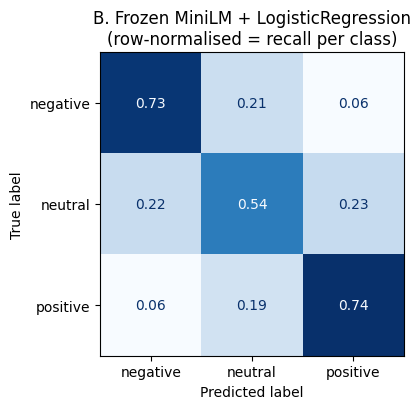

(0.695, 0.6691253802876713)

In [ ]:
# A single linear layer on top of frozen features. No hidden layers, no fine-tuning.
head = LogisticRegression(max_iter=3000, C=10.0, class_weight="balanced", n_jobs=-1)
head.fit(X_tr_emb, emb_train["y"])

pred_emb = head.predict(X_te_emb)
evaluate(test_df["y"], pred_emb, "B. Frozen MiniLM + LogisticRegression")

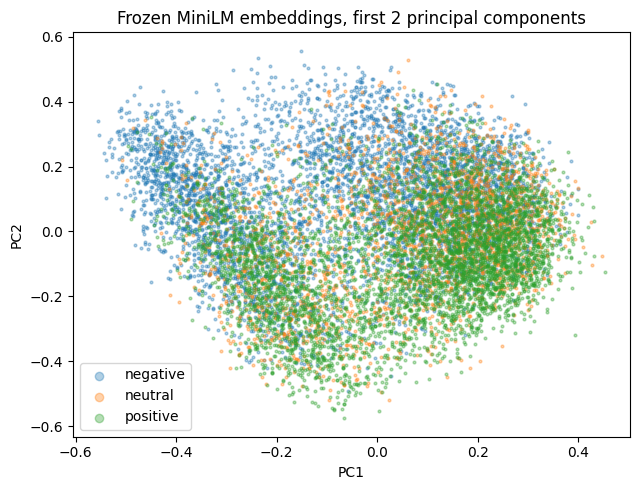

In [ ]:
# Do the embeddings separate the classes geometrically? Project to 2D with PCA.
# (PCA, not t-SNE/UMAP: it is linear, deterministic, and instant -- and if the classes are
#  linearly separable at all, PCA will hint at it.)
from sklearn.decomposition import PCA

proj = PCA(n_components=2, random_state=SEED).fit_transform(X_tr_emb)

plt.figure(figsize=(6.5, 5))
for i, label in enumerate(LABELS):
    m = (emb_train["y"].values == i)
    plt.scatter(proj[m, 0], proj[m, 1], s=4, alpha=0.35, label=label)
plt.legend(markerscale=3)
plt.title("Frozen MiniLM embeddings, first 2 principal components")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.tight_layout(); plt.show()

The clouds overlap heavily. This is the expected result and it is the lesson: **general-purpose semantic embeddings do not organise text by sentiment**, because they were never asked to. The classifier still extracts a usable signal — sentiment is *somewhere* in those 384 dimensions — but a large share of the representation is spent on topic, style and length.

Fine-tuning fixes this by moving the encoder's weights so the representation is reshaped *around the task*.


---
# Part 4 — Model C: Fine-Tuning RoBERTa  

Now we update the encoder itself. The recipe:

1. Load a pretrained encoder plus a randomly initialised classification head (`AutoModelForSequenceClassification`).
2. Tokenise the corpus into subwords with the model's own tokenizer.
3. Train end-to-end with a small learning rate (`2e-5`), a **linear warmup + decay** schedule, and **mixed precision** (`fp16`).
4. Weight the loss by inverse class frequency so the minority class is not ignored.
5. Select the checkpoint by **validation macro-F1**, not by loss.

**Why such a small learning rate?** The encoder already encodes a great deal about English. A large LR destroys that knowledge in the first few steps — "catastrophic forgetting". `1e-5` to `5e-5` is the standard band for encoder fine-tuning; the randomly initialised head could tolerate more, and discriminative learning rates exploit that, but a single small LR is the robust default.

**Why warmup?** The head starts random, so early gradients are large and noisy. Ramping the LR up over the first ~6% of steps stops those first updates from wrecking the pretrained weights.

In [ ]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)
from datasets import Dataset

MODEL_NAME = CFG["model_name"]
tokenizer  = AutoTokenizer.from_pretrained(MODEL_NAME)  # Load pretrained tokenizer

def to_hf(df):
    # Convert pandas DataFrame to Hugging Face Dataset and rename target column.
    return Dataset.from_pandas(
        df[["text", "y"]].rename(columns={"y": "labels"}),
        preserve_index=False
    )

def tokenize(batch):
    # Tokenize text and truncate sequences longer than max_len.
    return tokenizer(batch["text"], truncation=True, max_length=CFG["max_len"])

# Convert all splits to Hugging Face Datasets.
ds = {"train": to_hf(train_df), "validation": to_hf(val_df), "test": to_hf(test_df)}

# Tokenize datasets and remove the original text column.
ds = {k: v.map(tokenize, batched=True, remove_columns=["text"]) for k, v in ds.items()}

# Dynamically pad each batch to its longest sequence.
collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Sanity check: inspect the first few generated subword tokens.
sample = tokenizer(train_df["text"].iloc[0][:300], truncation=True, max_length=CFG["max_len"])
print("First 25 subword tokens:")
print(tokenizer.convert_ids_to_tokens(sample["input_ids"])[:25])

# Print the number of examples in each split.
print(f"\nTokenised splits: " + ", ".join(f"{k}={len(v):,}" for k, v in ds.items()))

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

First 25 subword tokens:
['<s>', 'I', 'Ġwill', 'Ġpre', 'face', 'Ġthis', 'Ġby', 'Ġsaying', 'ĠI', 'Ġjust', 'Ġreturned', 'Ġfrom', 'Ġliving', 'Ġin', 'ĠJapan', 'Ġfor', 'Ġtwo', 'Ġyears', '.', 'ĠI', 'Ġlove', 'Ġsushi', 'Ġand', 'Ġhave', 'Ġbeen']

Tokenised splits: train=16,000, validation=2,000, test=4,000


In [ ]:
# ---------------------------------------------------------------------
# Class-weighted loss.
# The Trainer's default loss is unweighted cross-entropy, which lets the model
# maximise accuracy by neglecting the minority class. We override compute_loss.
# ---------------------------------------------------------------------

from sklearn.utils.class_weight import compute_class_weight
import torch.nn as nn

# Compute weights inversely proportional to class frequency.
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_LABELS),
    y=train_df["y"].values
)
class_weights_t = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

print("class weights:", dict(zip(LABELS, class_weights.round(3))))


class WeightedTrainer(Trainer):
    # Override the default loss with weighted cross-entropy.
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels  = inputs.pop("labels")
        outputs = model(**inputs)

        # Apply higher loss weights to underrepresented classes.
        loss = nn.CrossEntropyLoss(weight=class_weights_t)(
            outputs.logits.view(-1, NUM_LABELS),
            labels.view(-1)
        )

        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):
    # Compute accuracy and macro-F1 after each evaluation.
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro")
    }

class weights: {'negative': np.float64(0.832), 'neutral': np.float64(1.655), 'positive': np.float64(0.837)}


In [ ]:
# ---------------------------------------------------------------------
# TrainingArguments. The evaluation-strategy keyword was renamed in transformers 4.46
# (`evaluation_strategy` -> `eval_strategy`), so we detect which one this version accepts.
# ---------------------------------------------------------------------
import inspect

args_kwargs = dict(
    output_dir="./ft_sentiment",
    learning_rate=CFG["lr"],
    per_device_train_batch_size=CFG["batch_size"],
    per_device_eval_batch_size=CFG["batch_size"] * 2,   # no gradients at eval -> bigger batches fit
    num_train_epochs=CFG["epochs"],
    weight_decay=CFG["weight_decay"],
    fp16=HAS_GPU,                    # mixed precision: ~2x faster, ~half the memory on a T4
    logging_steps=50,
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    report_to="none",                # disable W&B / TensorBoard auto-logging
    seed=SEED,
)

_params = inspect.signature(TrainingArguments.__init__).parameters
_strategy_key = "eval_strategy" if "eval_strategy" in _params else "evaluation_strategy"
args_kwargs[_strategy_key] = "epoch"
args_kwargs["save_strategy"] = "epoch"

training_args = TrainingArguments(**args_kwargs)
print(f"Using '{_strategy_key}=epoch'; fp16={HAS_GPU}")

Using 'eval_strategy=epoch'; fp16=True


In [ ]:
# ---------------------------------------------------------------------
# Train. Expect ~4-6 min on a T4 for roberta-base / 16k reviews / 2 epochs.
# ---------------------------------------------------------------------
set_seed()

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label=ID2LABEL,          # baked into the config so pipelines return readable labels
    label2id=LABEL2ID,
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=ds["train"],
    eval_dataset=ds["validation"],
    data_collator=collator,
    compute_metrics=compute_metrics,
)

t0 = time.time()
train_out = trainer.train()
print(f"\nFine-tuning finished in {(time.time()-t0)/60:.1f} min")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6:.1f}M")

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.574865,0.602298,0.780000,0.739572
2,0.430179,0.546483,0.800000,0.770064


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Fine-tuning finished in 5.9 min
Trainable parameters: 124.6M


=== C. Fine-tuned roberta-base ===
accuracy : 0.7957
macro-F1 : 0.7690

              precision    recall  f1-score   support

    negative      0.882     0.815     0.847      1557
     neutral      0.538     0.648     0.588       855
    positive      0.887     0.856     0.872      1588

    accuracy                          0.796      4000
   macro avg      0.769     0.773     0.769      4000
weighted avg      0.811     0.796     0.802      4000



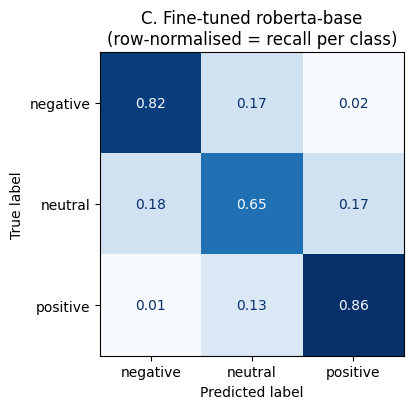

(0.79575, 0.7690127657370978)

In [ ]:
# Final evaluation on the held-out test set -- the first and only time we touch it.
pred_logits = trainer.predict(ds["test"])
pred_ft     = np.argmax(pred_logits.predictions, axis=-1)
prob_ft     = torch.softmax(torch.tensor(pred_logits.predictions), dim=-1).numpy()

evaluate(test_df["y"], pred_ft, f"C. Fine-tuned {MODEL_NAME}")

In [ ]:
# Did fine-tuning fix the negation / contrast probes that TF-IDF failed?
from transformers import pipeline

sentiment_pipe = pipeline("text-classification", model=model, tokenizer=tokenizer,
                          device=PIPE_DEVICE, truncation=True, max_length=CFG["max_len"])

ft_out = sentiment_pipe(probe_texts)
probe_df["finetuned_pred"] = [o["label"] for o in ft_out]
probe_df["ft_conf"]        = [round(o["score"], 2) for o in ft_out]
probe_df["ft_correct"]     = probe_df.expected == probe_df.finetuned_pred

display(probe_df[["text", "expected", "tfidf_pred", "finetuned_pred", "ft_conf", "ft_correct"]])
print(f"TF-IDF probe accuracy      : {probe_df.correct.mean():.0%}")
print(f"Fine-tuned probe accuracy  : {probe_df.ft_correct.mean():.0%}")

,text,expected,tfidf_pred,finetuned_pred,ft_conf,ft_correct
0,The food was great.,positive,positive,positive,0.97,True
1,The food was not great.,negative,negative,negative,0.73,True
2,I would not say the food was bad.,positive,negative,neutral,0.90,False
3,"Great food, but the service completely ruined the evening.",negative,negative,negative,0.54,True
4,"Terrible parking, but honestly the meal was outstanding.",positive,negative,positive,0.83,True
5,"Well, that was exactly the experience I was hoping for. Not.",negative,negative,negative,0.88,True


TF-IDF probe accuracy      : 67%
Fine-tuned probe accuracy  : 83%


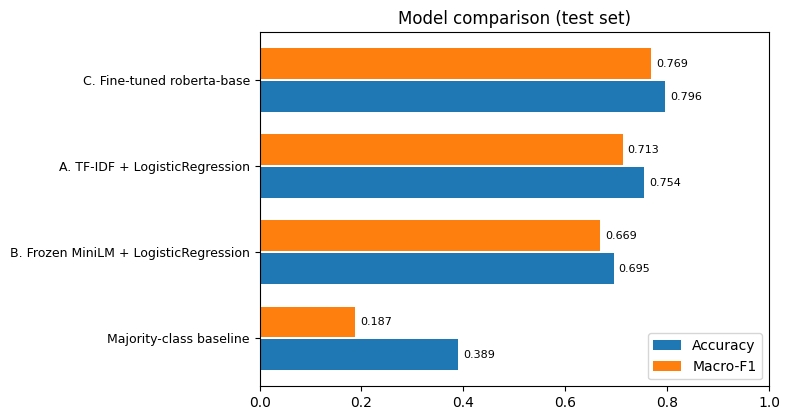

,Accuracy,Macro-F1
Majority-class baseline,0.3892,0.1868
B. Frozen MiniLM + LogisticRegression,0.6950,0.6691
A. TF-IDF + LogisticRegression,0.7545,0.7125
C. Fine-tuned roberta-base,0.7958,0.7690


In [ ]:
# ---------------------------------------------------------------------
# Model comparison so far.
# ---------------------------------------------------------------------
res_df = (pd.DataFrame(RESULTS).T
            .sort_values("macro_f1")
            .rename(columns={"accuracy": "Accuracy", "macro_f1": "Macro-F1"}))

fig, ax = plt.subplots(figsize=(8, 0.7 * len(res_df) + 1.5))
ypos = np.arange(len(res_df))
ax.barh(ypos - 0.19, res_df["Accuracy"], height=0.36, label="Accuracy")
ax.barh(ypos + 0.19, res_df["Macro-F1"], height=0.36, label="Macro-F1")
ax.set_yticks(ypos); ax.set_yticklabels(res_df.index, fontsize=9)
ax.set_xlim(0, 1); ax.legend(loc="lower right"); ax.set_title("Model comparison (test set)")
for i, (a, f) in enumerate(zip(res_df["Accuracy"], res_df["Macro-F1"])):
    ax.text(a + .01, i - 0.19, f"{a:.3f}", va="center", fontsize=8)
    ax.text(f + .01, i + 0.19, f"{f:.3f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

display(res_df.round(4))

## 4.1 What did the extra compute buy?

Interpret the table along **two** axes, not one:

| Model | Train time | Params updated | Inference cost | Typical use |
|---|---|---|---|---|
| TF-IDF + LogReg | seconds | ~10⁵ (sparse) | microseconds, CPU | Baseline; huge-volume, latency-critical filtering |
| Frozen MiniLM + head | seconds (after encoding) | ~10³ | one small forward pass | Few labels; embeddings reused for search/clustering |
| Fine-tuned RoBERTa | minutes on GPU | ~125 × 10⁶ | GPU or batched CPU | Best accuracy when labels and hardware exist |

The honest summary is that fine-tuning typically buys **5–12 macro-F1 points** over a well-tuned TF-IDF baseline on this kind of data — a real gain, concentrated almost entirely in the hard middle class and in negation/contrast cases, and paid for with a GPU dependency and a much heavier deployment.

**If the gap is small on your own data, the baseline is the right answer.** That is a legitimate and common outcome.


---
# Part 5 — Beyond Polarity: Emotion Detection

`negative` is not an action. Two negative reviews can demand completely different responses:

- *"I've emailed three times and no one has replied. This is unacceptable."* → **anger**, churn risk, escalate now.
- *"I was really looking forward to this and it just wasn't what I hoped."* → **sadness/disappointment**, recoverable with a goodwill gesture.

An emotion classifier adds that second dimension for free — no training required, because good public checkpoints exist. We use `j-hartmann/emotion-english-distilroberta-base`, fine-tuned on six Ekman emotions plus neutral.

This is also your first look at **model reuse**: most production NLP is composing existing checkpoints, not training new ones.

In [ ]:
EMOTION_MODEL = "j-hartmann/emotion-english-distilroberta-base"

# top_k=None returns the full distribution over emotions rather than only the argmax.
emotion_pipe = pipeline("text-classification", model=EMOTION_MODEL, top_k=None,
                        device=PIPE_DEVICE, truncation=True, max_length=256)

demo = [
    "I have emailed support three times about this and nobody has replied. Unacceptable.",
    "I was really looking forward to this and it just was not what I hoped for.",
    "Absolutely blown away, the staff went out of their way to help us.",
    "The invoice amount does not match the quote I was given.",
]
for text in demo:
    dist = {d["label"]: round(d["score"], 3) for d in emotion_pipe(text)[0]}
    top  = sorted(dist.items(), key=lambda kv: -kv[1])[:3]
    print(textwrap.fill(text, 95))
    print("   ->", ", ".join(f"{k}={v}" for k, v in top), "\n")

config.json:   0%|          | 0.00/1.00k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  329MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/294 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  329MB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

I have emailed support three times about this and nobody has replied. Unacceptable.
   -> disgust=0.665, anger=0.288, sadness=0.028 

I was really looking forward to this and it just was not what I hoped for.
   -> sadness=0.356, neutral=0.286, surprise=0.277 

Absolutely blown away, the staff went out of their way to help us.
   -> surprise=0.741, anger=0.15, disgust=0.071 

The invoice amount does not match the quote I was given.
   -> neutral=0.879, sadness=0.046, surprise=0.03 



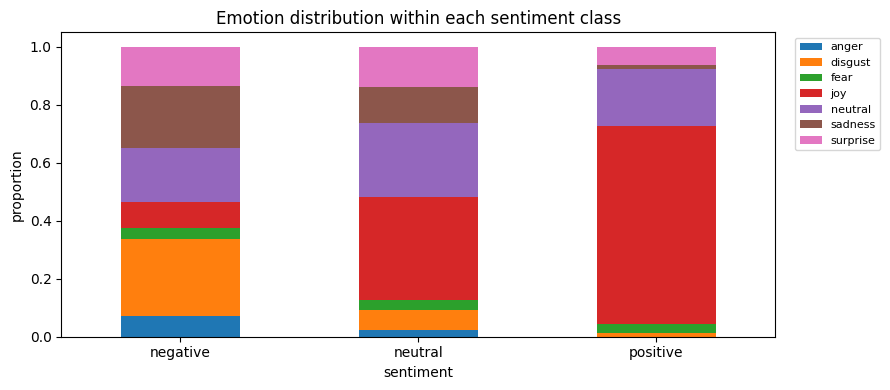

emotion,anger,disgust,fear,joy,neutral,sadness,surprise
sentiment,,,,,,,
negative,0.071,0.265,0.039,0.090,0.187,0.213,0.135
neutral,0.023,0.069,0.034,0.356,0.253,0.126,0.138
positive,0.000,0.013,0.032,0.684,0.196,0.013,0.063


In [ ]:
# Sample the test set and predict the dominant emotion for each review.
emo_sample = test_df.sample(min(400, len(test_df)), random_state=SEED).copy()

# Run the emotion classifier in batches.
emo_raw = emotion_pipe(emo_sample["text"].tolist(), batch_size=32)

# Keep the emotion with the highest predicted score.
emo_sample["emotion"] = [
    max(d, key=lambda x: x["score"])["label"] for d in emo_raw
]

# Cross-tabulate emotions against sentiment labels using row proportions.
ct = pd.crosstab(
    emo_sample["sentiment"],
    emo_sample["emotion"],
    normalize="index"
)
ct = ct.reindex(LABELS).fillna(0)

# Plot the emotion distribution within each sentiment class.
ct.plot(kind="bar", stacked=True, figsize=(9, 4))
plt.title("Emotion distribution within each sentiment class")
plt.ylabel("proportion")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

# Display the proportions rounded to three decimal places.
display(ct.round(3))

Note the structure inside the negative class: it splits into `anger` (confrontational, high churn risk) and `sadness`/`fear` (disappointed, still winnable). **That split is the operationally useful signal, and document-level sentiment alone destroys it.**

Note also that "neutral" reviews are dominated by the model's own `neutral` emotion plus a long tail — a reminder that our 3-star bucket mixes genuinely lukewarm text with strongly mixed text.

---
# Part 6 — Aspect-Based Sentiment Analysis  
Consider a real review:

> *"The pasta was genuinely excellent and the room is beautiful, but we waited 50 minutes for a table despite booking, and the bill had an item we never ordered."*

Document-level sentiment gives one label. What the business needs is:

| aspect | sentiment |
|---|---|
| food | positive |
| ambience | positive |
| wait time | **negative** |
| billing | **negative** |

**ABSA** produces that table. It is what converts "sentiment analysis" from a dashboard number into a work queue.

### Three ways to do ABSA

1. **Lexicon + clause segmentation** *(what we build first)* — split the review into clauses, match each clause to an aspect via keywords, classify each clause with our fine-tuned model. No extra training, fully transparent, easy to debug, and it exploits a genuine linguistic regularity: **contrastive conjunctions (`but`, `although`, `however`) mark polarity boundaries**.
2. **Aspect-conditioned classifier** *(demonstrated after)* — feed the model the pair `(review, aspect)` and let cross-attention resolve which span is relevant. More accurate on interleaved opinions.
3. **Sequence labelling / generative extraction** — jointly tag aspect terms and polarities (E2E-ABSA, InstructABSA). Most accurate, needs aspect-annotated training data.

In [ ]:
# ---------------------------------------------------------------------
# 6.1 Aspect discovery.
# Seed aspect categories using domain knowledge, then check corpus coverage.
# ---------------------------------------------------------------------
ASPECT_LEXICON = {
    "food_quality": ["food", "dish", "meal", "taste", "flavor", "flavour", "pasta", "pizza",
                     "chicken", "sauce", "portion", "menu", "cooked", "fresh", "dessert"],
    "service":      ["service", "staff", "waiter", "waitress", "server", "manager", "rude",
                     "friendly", "attentive", "host", "hostess", "employee"],
    "wait_time":    ["wait", "waited", "waiting", "slow", "quick", "queue", "line", "minutes",
                     "hour", "delay", "prompt", "reservation"],
    "price_value":  ["price", "prices", "expensive", "cheap", "value", "overpriced", "worth",
                     "bill", "charge", "charged", "cost", "affordable"],
    "ambience":     ["atmosphere", "ambience", "ambiance", "decor", "music", "noisy", "loud",
                     "clean", "dirty", "seating", "vibe", "comfortable"],
    "product":      ["product", "quality", "item", "works", "broke", "broken", "battery",
                     "app", "game", "device", "feature", "update"],
    "delivery":     ["delivery", "shipping", "arrived", "package", "order", "shipped", "late"],
}

# Check how often each aspect is mentioned in the test corpus.
sample_txt = test_df["text"].str.lower()
coverage = {
    a: sample_txt.str.contains("|".join(kw), regex=True).mean()
    for a, kw in ASPECT_LEXICON.items()
}

# Sort aspects by their frequency in the corpus.
coverage = dict(sorted(coverage.items(), key=lambda kv: -kv[1]))

for a, c in coverage.items():
    print(f"{a:>13} mentioned in {c:6.1%} of reviews")

# Keep only aspects mentioned in at least 3% of reviews.
ASPECTS = [a for a, c in coverage.items() if c >= 0.03]
print("\nAspects retained:", ASPECTS)

 food_quality mentioned in  61.3% of reviews
      service mentioned in  53.1% of reviews
      product mentioned in  41.1% of reviews
    wait_time mentioned in  40.5% of reviews
     delivery mentioned in  36.0% of reviews
  price_value mentioned in  35.9% of reviews
     ambience mentioned in  27.3% of reviews

Aspects retained: ['food_quality', 'service', 'product', 'wait_time', 'delivery', 'price_value', 'ambience']


In [ ]:
# ---------------------------------------------------------------------
# 6.2 Clause segmentation.
# Split at sentence boundaries and contrastive/coordinating conjunctions
# to separate clauses with potentially different sentiment polarities.
# ---------------------------------------------------------------------
CLAUSE_SPLIT = re.compile(
    r"(?<=[.!?])\s+"  # sentence boundary
    r"|\s*,?\s*\b(?:but|however|although|though|whereas|yet|except that)\b\s*"  # contrast markers
    r"|\s*;\s*",
    flags=re.IGNORECASE,
)

def split_clauses(text, min_len=15):
    # Return clauses long enough to contain a meaningful opinion.
    parts = [
        p.strip()
        for p in CLAUSE_SPLIT.split(text)
        if p and len(p.strip()) >= min_len
    ]
    return parts

def match_aspects(clause):
    # Find all aspects mentioned in the clause.
    low = clause.lower()
    return [
        a for a in ASPECTS
        if any(re.search(r"\b" + re.escape(k) + r"\w*", low)
               for k in ASPECT_LEXICON[a])
    ]

# Example review containing multiple aspects and sentiment polarities.
demo_review = (
    "The pasta was genuinely excellent and the room is beautiful, but we waited "
    "50 minutes for a table despite having a reservation, and the bill had an "
    "item on it we never ordered. The manager did apologise."
)

# Display each clause along with its detected aspects.
for c in split_clauses(demo_review):
    print(f"{str(match_aspects(c)):<40} | {c}")

['food_quality']                         | The pasta was genuinely excellent and the room is beautiful
['product', 'wait_time', 'delivery', 'price_value'] | we waited 50 minutes for a table despite having a reservation, and the bill had an item on it we never ordered.
['service']                              | The manager did apologise.


In [ ]:
# ---------------------------------------------------------------------
# 6.3 Clause-level sentiment using the fine-tuned sentiment model.
# The model was trained on whole reviews, so applying it to clauses is a
# train/inference mismatch and remains a limitation of this approach.
# ---------------------------------------------------------------------
def absa_extract(texts, batch_size=64):
    # Return one row for each (review, aspect, clause) combination.
    clause_rows = []

    for doc_id, text in enumerate(texts):
        # Split each review into clauses and detect their aspects.
        for clause in split_clauses(text):
            for aspect in match_aspects(clause):
                clause_rows.append({
                    "doc_id": doc_id,
                    "aspect": aspect,
                    "clause": clause
                })

    # Return an empty DataFrame if no aspects were detected.
    if not clause_rows:
        return pd.DataFrame(
            columns=["doc_id", "aspect", "clause", "sentiment", "score"]
        )

    out = pd.DataFrame(clause_rows)

    # Predict sentiment for each clause using the fine-tuned model.
    preds = sentiment_pipe(out["clause"].tolist(), batch_size=batch_size)
    out["sentiment"] = [p["label"] for p in preds]
    out["score"]     = [p["score"] for p in preds]

    return out


# Use fewer reviews in FAST_MODE to reduce runtime during experimentation.
absa_docs = test_df["text"].tolist()[:(300 if FAST_MODE else 1200)]

t0 = time.time()
absa_df = absa_extract(absa_docs)

print(
    f"Extracted {len(absa_df):,} (review, aspect) opinions from "
    f"{len(absa_docs):,} reviews in {time.time()-t0:.1f}s"
)

# Measure the fraction of reviews where at least one aspect was detected.
print(
    f"Reviews with >=1 aspect detected: "
    f"{absa_df.doc_id.nunique()/len(absa_docs):.1%}"
)

# Inspect a few extracted aspect-level opinions.
display(absa_df.head(8))

Extracted 6,212 (review, aspect) opinions from 1,200 reviews in 10.6s
Reviews with >=1 aspect detected: 92.2%


,doc_id,aspect,clause,sentiment,score
0,0,food_quality,"We had our anniversary dinner there, we wanted top notch sea food and boy did we get it!!",positive,0.984104
1,0,service,Our service was fantastic and our night was topped off with the manager delivering us our desert.,positive,0.988145
2,0,food_quality,She asked how our meal was as well as congratulating us on our special night.,positive,0.895377
3,0,food_quality,"I give five stars to the food the staff especially the manager \""Kari\"" it showed great hospitality.",positive,0.916726
4,0,service,"I give five stars to the food the staff especially the manager \""Kari\"" it showed great hospitality.",positive,0.916726
5,1,wait_time,Made reservations and was asked if we were celebrating anything special.,neutral,0.533688
6,1,service,"Told her it was our anniversary and when we arrived the hostess, waitress and servers all wished us a happy anniversary.",positive,0.867573
7,1,wait_time,"Told her it was our anniversary and when we arrived the hostess, waitress and servers all wished us a happy anniversary.",positive,0.867573


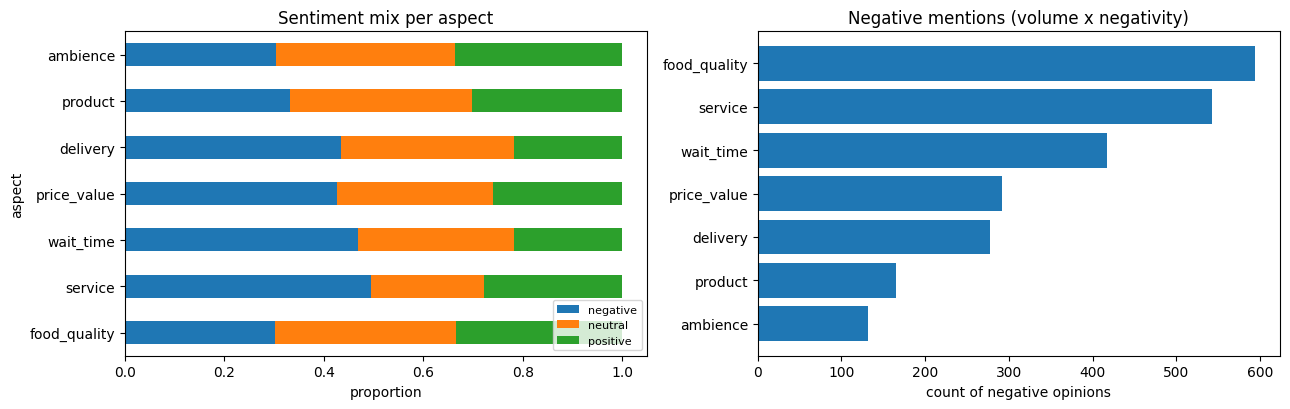

sentiment,negative,neutral,positive,mentions,neg_mentions
aspect,,,,,
food_quality,0.302,0.364,0.335,1970,594
service,0.495,0.228,0.278,1098,543
wait_time,0.469,0.313,0.218,889,417
price_value,0.426,0.314,0.260,685,292
delivery,0.434,0.348,0.217,640,278
product,0.333,0.365,0.302,496,165
ambience,0.304,0.359,0.336,434,132


In [ ]:
# ---------------------------------------------------------------------
# 6.4 Aggregate results into a product-owner-friendly report.
# Prioritize aspects by both volume and negativity.
# ---------------------------------------------------------------------

# Calculate the sentiment distribution for each aspect.
pivot = (
    pd.crosstab(
        absa_df["aspect"],
        absa_df["sentiment"],
        normalize="index"
    )
    .reindex(columns=LABELS)
    .fillna(0)
)

# Count how often each aspect is mentioned.
volume = absa_df["aspect"].value_counts()

report = pivot.copy()
report["mentions"] = volume

# Estimate the number of negative opinions for each aspect.
report["neg_mentions"] = (
    report["negative"] * report["mentions"]
).round().astype(int)

# Rank aspects by the number of negative mentions.
report = report.sort_values("neg_mentions", ascending=False)

# Visualize sentiment distribution and negative-mention volume.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

pivot.loc[report.index].plot(kind="barh", stacked=True, ax=axes[0])
axes[0].set_title("Sentiment mix per aspect")
axes[0].set_xlabel("proportion")
axes[0].legend(fontsize=8, loc="lower right")

axes[1].barh(report.index[::-1], report["neg_mentions"][::-1])
axes[1].set_title("Negative mentions (volume x negativity)")
axes[1].set_xlabel("count of negative opinions")

plt.tight_layout()
plt.show()

# Display the aggregated report.
display(report.round(3))

**This table is the deliverable.** It says which part of the business is generating the most customer pain, in absolute terms, from unstructured text nobody read manually. Track it week over week and you have a regression test for customer experience.

In [ ]:
# ---------------------------------------------------------------------
# 6.5 (Optional) Dedicated aspect-conditioned ABSA model.
# The model predicts sentiment for a specific aspect, which can handle
# interleaved opinions better than clause-level sentiment.
# ---------------------------------------------------------------------
ABSA_MODEL = "yangheng/deberta-v3-base-absa-v1.1"

try:
    # Load the ABSA model; this may require a large download and sentencepiece.
    absa_pipe = pipeline(
        "text-classification",
        model=ABSA_MODEL,
        device=PIPE_DEVICE,
        truncation=True,
        max_length=256
    )

    # Example containing different sentiments for different aspects.
    tricky = (
        "The food was incredible but the service was so slow we almost left, "
        "and honestly for the price I expected better."
    )
    print(textwrap.fill(tricky, 95), "\n")

    for aspect in ["food", "service", "price"]:
        # Append the target aspect using [SEP] as expected by the model.
        r = absa_pipe(f"{tricky} [SEP] {aspect}")[0]
        print(f"  {aspect:>8} -> {r['label']:<9} ({r['score']:.2f})")

    # Compare against the clause-level approach from Section 6.3.
    print("\nFor comparison, our clause-level pipeline on the same review:")
    for _, row in absa_extract([tricky]).iterrows():
        print(
            f"  {row.aspect:>13} -> {row.sentiment:<9} "
            f"({row.score:.2f}) | {row.clause[:60]}"
        )

except Exception as e:
    # Keep the rest of the notebook usable if the optional model fails.
    print(
        f"Dedicated ABSA model unavailable "
        f"({type(e).__name__}: {str(e)[:100]})."
    )
    print(
        "The clause-level pipeline from 6.3 remains fully functional "
        "-- skip this cell."
    )

config.json:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  738MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/372 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/18.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

The food was incredible but the service was so slow we almost left, and honestly for the price
I expected better. 

      food -> Positive  (0.99)
   service -> Negative  (1.00)
     price -> Negative  (0.99)

For comparison, our clause-level pipeline on the same review:
   food_quality -> positive  (0.99) | The food was incredible
        service -> negative  (0.96) | the service was so slow we almost left, and honestly for the
      wait_time -> negative  (0.96) | the service was so slow we almost left, and honestly for the
    price_value -> negative  (0.96) | the service was so slow we almost left, and honestly for the


---
# Part 7 — Zero-Shot Routing  

New feedback categories appear constantly, and you never have labels on day one. **Zero-shot classification** via natural language inference solves this: the model treats your candidate label as a hypothesis ("This example is about *billing*") and scores whether the review entails it.

Two honest facts about zero-shot:

- On a task you have labels for, a fine-tuned model **beats it comfortably**. Zero-shot is not a replacement for supervision.
- On a task you have *no* labels for, it works today, and it is how you bootstrap your first labelled set.

In [ ]:
ZS_MODELS = ["MoritzLaurer/deberta-v3-base-zeroshot-v2.0", "facebook/bart-large-mnli"]

zs_pipe = None
for m in ZS_MODELS:
    try:
        zs_pipe = pipeline("zero-shot-classification", model=m, device=PIPE_DEVICE)
        print("Zero-shot model:", m)
        break
    except Exception as e:
        print(f"[skip] {m}: {type(e).__name__}")

ROUTING_LABELS = ["billing or payment problem", "delivery or shipping problem",
                  "staff behaviour", "product quality defect",
                  "waiting time", "praise or compliment"]

tickets = [
    "Charged twice for the same order and the refund still has not shown up after two weeks.",
    "The courier left the parcel in the rain and it was soaked through.",
    "The girl at the counter was incredibly patient with my mother, we really appreciated it.",
    "Screen started flickering after four days of normal use.",
]

if zs_pipe is not None:
    # multi_label=False -> scores form a distribution over the candidate labels.
    for t in tickets:
        r = zs_pipe(t, ROUTING_LABELS, multi_label=False)
        print(textwrap.fill(t, 95))
        print(f"   -> {r['labels'][0]}  ({r['scores'][0]:.2f})   "
              f"| runner-up: {r['labels'][1]} ({r['scores'][1]:.2f})\n")

config.json:   0%|          | 0.00/1.02k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  369MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

Zero-shot model: MoritzLaurer/deberta-v3-base-zeroshot-v2.0
Charged twice for the same order and the refund still has not shown up after two weeks.
   -> billing or payment problem  (0.94)   | runner-up: waiting time (0.06)

The courier left the parcel in the rain and it was soaked through.
   -> delivery or shipping problem  (0.72)   | runner-up: staff behaviour (0.22)

The girl at the counter was incredibly patient with my mother, we really appreciated it.
   -> staff behaviour  (0.68)   | runner-up: praise or compliment (0.31)

Screen started flickering after four days of normal use.
   -> product quality defect  (0.98)   | runner-up: waiting time (0.01)



In [ ]:
# How much worse is zero-shot than our fine-tuned model on the SAME sentiment task?
if zs_pipe is not None:
    zs_eval = test_df.sample(min(200, len(test_df)), random_state=SEED)
    # Verbalise the classes: label wording materially changes zero-shot accuracy.
    verbaliser = {"negative": "a negative review", "neutral": "a mixed or neutral review",
                  "positive": "a positive review"}
    cand = [verbaliser[l] for l in LABELS]
    inv  = {v: k for k, v in verbaliser.items()}

    t0 = time.time()
    zs_out  = zs_pipe(zs_eval["text"].str[:800].tolist(), cand, multi_label=False, batch_size=16)
    zs_pred = [LABEL2ID[inv[o["labels"][0]]] for o in zs_out]
    print(f"Zero-shot inference on {len(zs_eval)} reviews took {time.time()-t0:.1f}s\n")

    zs_f1 = f1_score(zs_eval["y"], zs_pred, average="macro")
    ft_f1 = f1_score(zs_eval["y"], pred_ft[[test_df.index.get_loc(i) for i in zs_eval.index]],
                     average="macro")
    print(f"zero-shot  macro-F1 : {zs_f1:.4f}")
    print(f"fine-tuned macro-F1 : {ft_f1:.4f}   (same 200 reviews)")

Zero-shot inference on 200 reviews took 3.5s

zero-shot  macro-F1 : 0.6994
fine-tuned macro-F1 : 0.7555   (same 200 reviews)


---
# Part 8 — Explaining Individual Predictions  

"The model says negative" is not defensible to a customer, a regulator, or an engineer debugging a false alarm. **LIME** (Local Interpretable Model-agnostic Explanations) answers *which words drove this specific prediction*:

1. Take one review; generate hundreds of perturbed copies with random words removed.
2. Get the model's probability for each copy.
3. Fit a **sparse linear model** on (perturbation → probability), weighted by similarity to the original.
4. The linear coefficients are the local word attributions.

It is model-agnostic and intuitive. Its caveats matter: explanations are **local** (they say nothing about global behaviour), **approximate**, and slightly **stochastic** between runs.

In [ ]:
from lime.lime_text import LimeTextExplainer

def predict_proba_texts(texts):
    # LIME expects a function mapping texts to class probabilities.
    out = np.zeros((len(texts), NUM_LABELS))
    B = 64

    for i in range(0, len(texts), B):
        # Tokenize a batch and move it to the model's device.
        batch = tokenizer(
            list(texts[i:i+B]),
            truncation=True,
            max_length=CFG["max_len"],
            padding=True,
            return_tensors="pt"
        ).to(DEVICE)

        with torch.no_grad():
            logits = model(**batch).logits

        # Convert logits to probabilities.
        out[i:i+B] = torch.softmax(logits, dim=-1).cpu().numpy()

    return out


explainer = LimeTextExplainer(class_names=LABELS, random_state=SEED)

# Select a misclassified review; errors are especially useful for explanation.
errors = test_df.reset_index(drop=True)[pred_ft != test_df["y"].values]
target = errors.iloc[0] if len(errors) else test_df.iloc[0]
target_text = target["text"][:900]

# Generate a LIME explanation for the model's prediction.
exp = explainer.explain_instance(
    target_text,
    predict_proba_texts,
    num_features=12,
    num_samples=400 if FAST_MODE else 800,
    labels=list(range(NUM_LABELS))
)

# Get the model's predicted label for the selected review.
pred_label = ID2LABEL[
    int(np.argmax(predict_proba_texts([target_text])[0]))
]

print(textwrap.fill(target_text, 100))
print(f"\ngold = {target['sentiment']}   |   predicted = {pred_label}\n")

# Display words that most strongly support or oppose the prediction.
for w, wt in exp.as_list(label=LABEL2ID[pred_label]):
    bar = "#" * int(abs(wt) * 60)
    print(f"  {w:>18}  {'+' if wt > 0 else '-'}{bar} {wt:+.3f}")

The parking lot is all done now, so getting in and out is much less difficult. \n\nEither this place
is set up oddly or I am because I can never find anything there. I wander around until either
finding somebody or giving up (it's about 50/50).

gold = neutral   |   predicted = negative

                less  -######### -0.160
             parking  +##### +0.092
               never  +##### +0.086
            anything  +#### +0.079
                  up  +#### +0.071
                 all  -#### -0.067
                this  +### +0.063
              giving  +### +0.055
                find  +### +0.053
             nEither  +### +0.052
                   I  +### +0.052
               place  +## +0.046


In [ ]:
# LIME's own HTML rendering: colour-coded contributions in context.
exp.show_in_notebook(text=True)

---
# Part 9 — Error Analysis and Calibration  
The single highest-value hour in any classification project is spent reading the model's mistakes. We look at three things:

1. **Where the errors concentrate** — which class pairs get confused.
2. **Confident errors** — high-probability mistakes are either genuine model failures or label noise, and telling them apart matters.
3. **Calibration** — is a probability of 0.9 actually right 90% of the time? Uncalibrated scores make every downstream threshold arbitrary.

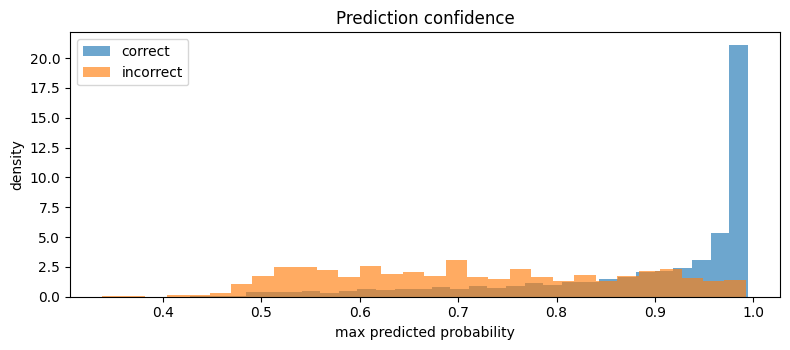

mean confidence when correct   : 0.891
mean confidence when incorrect : 0.716
errors above 0.90 confidence   : 128 of 817 errors


In [ ]:
# --- Confidence distribution: correct vs. incorrect predictions ---
conf = prob_ft.max(axis=1)
correct = pred_ft == test_df["y"].values

# Compare the confidence distributions of correct and incorrect predictions.
plt.figure(figsize=(8, 3.6))
plt.hist(conf[correct], bins=30, alpha=0.65, label="correct", density=True)
plt.hist(conf[~correct], bins=30, alpha=0.65, label="incorrect", density=True)
plt.xlabel("max predicted probability")
plt.ylabel("density")
plt.title("Prediction confidence")
plt.legend()
plt.tight_layout()
plt.show()

# Summarize confidence for correct and incorrect predictions.
print(f"mean confidence when correct   : {conf[correct].mean():.3f}")
print(f"mean confidence when incorrect : {conf[~correct].mean():.3f}")

# Count high-confidence mistakes.
print(
    f"errors above 0.90 confidence   : {(conf[~correct] > 0.90).sum()} "
    f"of {(~correct).sum()} errors"
)

In [ ]:
# --- Inspect the most confident mistakes ---
err_df = test_df.reset_index(drop=True).copy()

# Add predicted label and confidence to each test example.
err_df["pred"] = [ID2LABEL[i] for i in pred_ft]
err_df["conf"] = conf

# Keep misclassified examples and rank them by confidence.
worst = (
    err_df[err_df["pred"] != err_df["sentiment"]]
    .sort_values("conf", ascending=False)
)

# Display the four most confident errors for manual inspection.
for _, r in worst.head(4).iterrows():
    print("=" * 100)
    print(f"gold={r.sentiment}  pred={r['pred']}  conf={r.conf:.2f}")
    print(textwrap.fill(r.text[:600], 100))

print("=" * 100)
print("\nAsk of each: is the MODEL wrong, or is the LABEL wrong?")

gold=neutral  pred=negative  conf=0.99
DO NOT STAY HERE! DO NOT SPEND YOUR MONEY TO BE PISSED OFF. This was like a stay at the Bates Motel
without the murder. The dirt and stains all over my room was the good part. Pubiic hair all over the
room made me checkout  within 5 minutes of walking into the room. You have been warned do not stay
here.
gold=neutral  pred=negative  conf=0.99
I have been here 4 times in my lifetime and every time I go I experience the worst service. 18 year
olds that could give two sh*ts. With 4 table sections I expect a lot more. All I ever see if staff
standing around doing nothing. I have been in the food industry a long to time so yes i know i am my
own worst enemy when i go out to eat, but find some better servers. You get 3 stars for your food. I
will never go back.
gold=neutral  pred=negative  conf=0.99
The food here was lovely however, the server was a complete snob!! As soon as my party of 4 stated
that we were all okay with water at the moment her attitu

In [ ]:
# --- Check whether performance degrades on longer reviews ---
lens = err_df["text"].str.split().str.len()

# Group reviews into length-based buckets.
buckets = pd.cut(
    lens,
    [0, 50, 100, 200, 10**6],
    labels=["<50", "50-100", "100-200", ">200"]
)

rows = []

for b in buckets.cat.categories:
    m = (buckets == b).values

    # Skip buckets with too few examples for a meaningful comparison.
    if m.sum() > 20:
        rows.append({
            "length": b,
            "n": int(m.sum()),
            "accuracy": accuracy_score(err_df["y"][m], pred_ft[m]),
            "macro_f1": f1_score(err_df["y"][m], pred_ft[m], average="macro")
        })

# Display performance across review-length buckets.
display(pd.DataFrame(rows))

# Note that long reviews may lose information due to model truncation.
print(
    f"(reviews longer than max_len={CFG['max_len']} subwords are right-truncated)"
)

,length,n,accuracy,macro_f1
0,<50,906,0.821192,0.774335
1,50-100,1093,0.807868,0.784010
2,100-200,1221,0.800983,0.782410
3,>200,780,0.741026,0.708264


(reviews longer than max_len=192 subwords are right-truncated)


A softmax score is not a probability. A model that outputs 0.95 may be right only 80% of the time, and every downstream rule you build — auto-close above 0.9, route the rest to a human — silently inherits that error.

Temperature scaling is the standard one-parameter fix: divide the logits by a single scalar T learned on the validation set. Because dividing every logit by the same number cannot change which one is largest, it repairs the probabilities without altering a single prediction.

In [ ]:
# ---------------------------------------------------------------------
# Temperature scaling: calibrate confidence without changing predictions.
# Learn a single temperature T on the validation set and apply it to test logits.
# ---------------------------------------------------------------------
val_logits = trainer.predict(ds["validation"]).predictions
val_y = val_df["y"].values

def ece(probs, y, n_bins=10):
    # Measure the gap between confidence and accuracy across probability bins.
    conf_, pred_ = probs.max(1), probs.argmax(1)
    total = 0.0
    edges = np.linspace(0, 1, n_bins + 1)

    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf_ > lo) & (conf_ <= hi)
        if m.sum():
            total += m.mean() * abs(
                (pred_[m] == y[m]).mean() - conf_[m].mean()
            )

    return total


# Search for the temperature that minimizes validation cross-entropy.
logits_t = torch.tensor(val_logits)
best_T, best_nll = 1.0, float("inf")

for T in np.arange(0.5, 3.01, 0.05):
    nll = nn.CrossEntropyLoss()(
        logits_t / T,
        torch.tensor(val_y)
    ).item()

    if nll < best_nll:
        best_T, best_nll = float(T), nll


# Convert raw and temperature-scaled test logits to probabilities.
raw_probs = torch.softmax(
    torch.tensor(pred_logits.predictions), -1
).numpy()

cal_probs = torch.softmax(
    torch.tensor(pred_logits.predictions) / best_T, -1
).numpy()

print(
    f"optimal temperature T = {best_T:.2f}   "
    f"(T>1 means the model was over-confident)"
)
print(f"ECE before scaling : {ece(raw_probs, test_df['y'].values):.4f}")
print(f"ECE after  scaling : {ece(cal_probs, test_df['y'].values):.4f}")
print(
    f"accuracy unchanged : "
    f"{accuracy_score(test_df['y'], cal_probs.argmax(1)):.4f}"
)

ECE compressed calibration into one number, which is convenient but hides where the model goes wrong. A model can be well calibrated at 0.6 and badly over-confident at 0.95 and still post a respectable average.

The reliability diagram unpacks that average. Each point is one confidence bin, plotted as claimed confidence (x) against delivered accuracy (y). Perfect calibration is the diagonal; points below the line are over-confidence, points above are under-confidence — and the shape tells you which part of the confidence range you can actually trust.

In [ ]:
# --- Reliability diagram: perfectly calibrated predictions lie on the diagonal ---
def reliability(probs, y, ax, title, n_bins=10):
    # Get confidence and predicted class for each example.
    c, p = probs.max(1), probs.argmax(1)
    edges = np.linspace(0, 1, n_bins + 1)
    xs, ys = [], []

    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (c > lo) & (c <= hi)

        # Ignore bins with too few examples.
        if m.sum() > 5:
            xs.append(c[m].mean())
            ys.append((p[m] == y[m]).mean())

    # Compare model calibration against perfect calibration.
    ax.plot([0, 1], [0, 1], "--", color="gray", label="perfect")
    ax.plot(xs, ys, "o-", label="model")

    ax.set_xlabel("confidence")
    ax.set_ylabel("accuracy")
    ax.set_title(title)
    ax.legend(fontsize=8)


# Compare calibration before and after temperature scaling.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
reliability(
    raw_probs,
    test_df["y"].values,
    axes[0],
    "Before temperature scaling"
)
reliability(
    cal_probs,
    test_df["y"].values,
    axes[1],
    f"After (T = {best_T:.2f})"
)

plt.tight_layout()
plt.show()

**Why calibration is a deployment requirement, not a nicety.** Feedback systems auto-route below a confidence threshold and send the rest to humans. If 0.9 really means 90%, you can compute exactly how many mistakes an automation threshold lets through and set it against a business tolerance. If it does not, the threshold is a guess.

---
# Wrap-Up

## Honest limitations of what we built

1. **Sarcasm and irony remain unsolved.** "Fantastic, another hour on hold." Detecting it needs prosody, context, or user history that plain text does not carry.
2. **Star ratings are a proxy label.** They encode delivery delays and coupon failures that the text never mentions, which puts a hard ceiling on achievable accuracy.
3. **Train/inference mismatch in ABSA.** We trained on whole reviews and predict on clauses. A production system fine-tunes on clause- or aspect-annotated data (SemEval-2014 Task 4 is the standard starting point).
4. **Domain shift is severe.** A model fine-tuned on restaurant reviews degrades sharply on banking complaints. Always re-evaluate on your own corpus before trusting a number from a paper.
5. **A hand-written lexicon encodes the author's assumptions** about which aspects matter, and will silently miss the ones nobody thought of.
6. **Fairness was not audited.** Sentiment models are documented to score dialect variation and non-native English differently. Any customer-facing deployment needs a subgroup evaluation before launch.



## References

- Zhang, Zhao & LeCun (2015). *Character-level Convolutional Networks for Text Classification* — the Yelp/Amazon benchmark corpora.
- Sun et al. (2019). *How to Fine-Tune BERT for Text Classification?* — truncation strategies, layer-wise learning rates.
- Pontiki et al. (2014). *SemEval-2014 Task 4: Aspect Based Sentiment Analysis* — the standard ABSA benchmark.
- Ribeiro et al. (2016). *"Why Should I Trust You?"* — LIME.
- Guo et al. (2017). *On Calibration of Modern Neural Networks* — temperature scaling.
- Ribeiro et al. (2020). *Beyond Accuracy: Behavioral Testing of NLP Models with CheckList* — structured probing.
- Hugging Face, *NLP Course*, chapters 3 and 7 — https://huggingface.co/learn/nlp-course